# Deep Learning Project 1: Custom ResNet on CIFAR-10
## Parameter count, trained checkpoint, test accuracy and progress

Team **The Distillers**: Matan Tsafrir (mt6037), Jonathan David (yd3245).
Full details are in our report; this notebook verifies the final model and shows its results.

### Summary
| | |
| :--- | :--- |
| **Architecture** | CustomResNet "architecture B": blocks `[3, 7, 6, 1]`, channels `[40, 80, 160, 320]`, 3x3 convolutions, average-pooling shortcuts |
| **Trainable parameters** | **4,976,530** (< 5,000,000) |
| **Training** | All 50,000 training images, 1200 epochs, SGD (momentum 0.9, lr 0.05, cosine schedule, weight decay 2e-4), AutoAugment, random crop, horizontal flip, Cutout (p = 0.7), label smoothing 0.1 |
| **Test-time augmentation** | Each test image's prediction is averaged with that of its mirror image |
| **Final test accuracy** | **87.7%** on the private Kaggle leaderboard (rank 21 of 81); 89.9% on the public leaderboard |
| **Validation accuracy** | None: the final model was trained on all labeled images |


In [1]:
import os
import sys
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.append(os.path.abspath('.'))
import models

print(f'PyTorch version: {torch.__version__}')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Matplotlib is building the font cache; this may take a moment.


PyTorch version: 2.15.0
Device: cpu


## 1. Build the model and count its parameters

The model is built from the same config file that was used to train the final model.

In [2]:
config_path = 'configs/fulldata_arch_B_SGD_1200_low_weight_decay.yaml'
with open(config_path) as f:
    config = yaml.safe_load(f)

model_cfg = {k: v for k, v in config['model'].items() if k != 'name'}
net = models.CustomResNet(**model_cfg).to(device)

trainable_params = sum(p.numel() for p in net.parameters() if p.requires_grad)
max_params = config.get('max_params', 5_000_000)

print(f"Blocks per stage  : {config['model']['blocks_per_layer']}")
print(f"Channels per stage: {config['model']['channels']}")
print(f"Shortcut type     : {config['model']['shortcut_type']}")
print(f'Trainable params  : {trainable_params:,}')
print(f'Budget            : {max_params:,}')
assert trainable_params <= max_params, 'Parameter budget exceeded!'
print('Within the 5M-parameter budget.')

Blocks per stage  : [3, 7, 6, 1]
Channels per stage: [40, 80, 160, 320]
Shortcut type     : avgpool
Trainable params  : 4,976,530
Budget            : 5,000,000
Within the 5M-parameter budget.


## 2. Load the trained checkpoint

We load the saved weights into the model with `strict=True`, which fails if any weight is missing or has the wrong shape. The checkpoint was saved from a `DataParallel` model, so its keys carry a `module.` prefix that we strip.

In [3]:
checkpoint_path = os.path.join(config['checkpoint']['dir'], config['checkpoint']['filename'])
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)

state_dict = {k.removeprefix('module.'): v for k, v in checkpoint['net'].items()}
result = net.load_state_dict(state_dict, strict=True)
net.eval()

loaded_params = sum(p.numel() for p in net.parameters())
print(f'Checkpoint        : {checkpoint_path}')
print(f'Load result       : {result}')
print(f"Epochs trained    : {checkpoint['epoch'] + 1}")
print(f"Final train acc.  : {checkpoint['acc']:.2f}% (on augmented training images)")
print(f'Parameters loaded : {loaded_params:,}')

Checkpoint        : ./checkpoints/fulldata_arch_B_sgd_1200_low_weight_decay/best.pth
Load result       : <All keys matched successfully>
Epochs trained    : 1200
Final train acc.  : 97.93% (on augmented training images)
Parameters loaded : 4,976,530


## 3. Final test accuracy

The Kaggle test labels are not public, so test accuracy cannot be computed here; it is the score Kaggle reported for our submitted predictions (`Final_submission_fulldata_arch_B_1200_low_weight_decay.csv`, produced by this checkpoint with `predict.py --tta --tta_mode flip`).

In [4]:
print('Final test accuracy (private Kaggle leaderboard): 87.7%  (rank 21 of 81)')
print('Public Kaggle leaderboard                       : 89.9%')
print(f'Trainable parameters                            : {trainable_params:,}')

Final test accuracy (private Kaggle leaderboard): 87.7%  (rank 21 of 81)
Public Kaggle leaderboard                       : 89.9%
Trainable parameters                            : 4,976,530


## 4. Progress toward the final model

Kaggle scores of the successive models that led to our final model (the same data as Figure 2 of our report). Each step is labeled by its main change; some steps also changed the layout or training length, so they are milestones rather than controlled comparisons. We made decisions on the public score; private scores were revealed only after the competition closed. The first four steps were submitted as plain predictions, the last three with flip test-time augmentation.

                                           Step Epochs  Parameters  Public  Private
Starting point (ResNet-18 layout, 0.625x width)    ~50     4368690   0.784    0.766
                            + data augmentation    ~50     4368690   0.809    0.785
   + average-pooling shortcut, [3,3,3,2] layout     80     4974610   0.828    0.805
                       Architecture B [3,7,6,1]    100     4976530   0.856    0.808
                                  + AutoAugment    300     4976530   0.882    0.857
                       Final recipe, 600 epochs    600     4976530   0.897    0.874
        Final recipe, 1200 epochs (final model)   1200     4976530   0.899    0.877


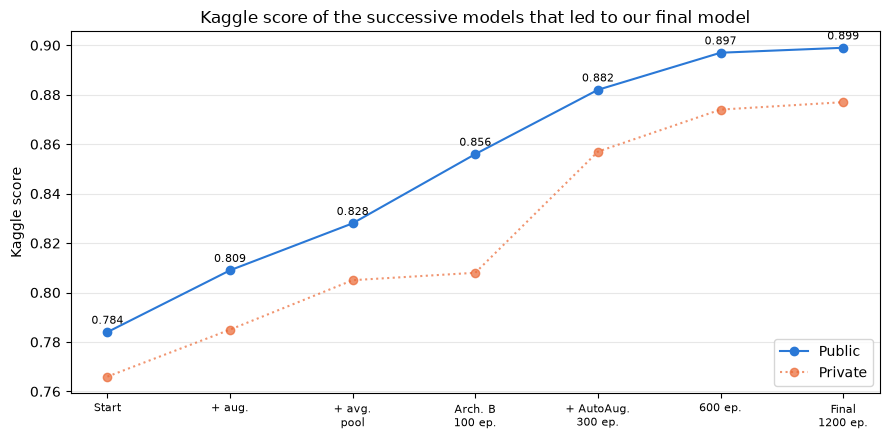

In [5]:
steps = pd.DataFrame([
    ('Starting point (ResNet-18 layout, 0.625x width)', '~50',  4_368_690, 0.784, 0.766),
    ('+ data augmentation',                             '~50',  4_368_690, 0.809, 0.785),
    ('+ average-pooling shortcut, [3,3,3,2] layout',    '80',   4_974_610, 0.828, 0.805),
    ('Architecture B [3,7,6,1]',                        '100',  4_976_530, 0.856, 0.808),
    ('+ AutoAugment',                                   '300',  4_976_530, 0.882, 0.857),
    ('Final recipe, 600 epochs',                        '600',  4_976_530, 0.897, 0.874),
    ('Final recipe, 1200 epochs (final model)',         '1200', 4_976_530, 0.899, 0.877),
], columns=['Step', 'Epochs', 'Parameters', 'Public', 'Private'])
print(steps.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(steps))
ax.plot(x, steps['Public'], 'o-', color='#2a78d6', label='Public')
ax.plot(x, steps['Private'], 'o:', color='#eb6834', alpha=0.7, label='Private')
for xi, v in zip(x, steps['Public']):
    ax.annotate(f'{v:.3f}', (xi, v), textcoords='offset points', xytext=(0, 6), ha='center', fontsize=8)
labels = ['Start', '+ aug.', '+ avg.\npool', 'Arch. B\n100 ep.', '+ AutoAug.\n300 ep.', '600 ep.', 'Final\n1200 ep.']
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel('Kaggle score')
ax.set_title('Kaggle score of the successive models that led to our final model')
ax.grid(axis='y', alpha=0.3)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 5. Predicted class distribution on the test set

A sanity check: the final submission's predictions are spread roughly evenly over the 10 classes (the test set has 2,000 images).

Predictions: 2,000
  0 airplane    175
  1 automobile  217
  2 bird        211
  3 cat         201
  4 deer        196
  5 dog         209
  6 frog        177
  7 horse       211
  8 ship        205
  9 truck       198


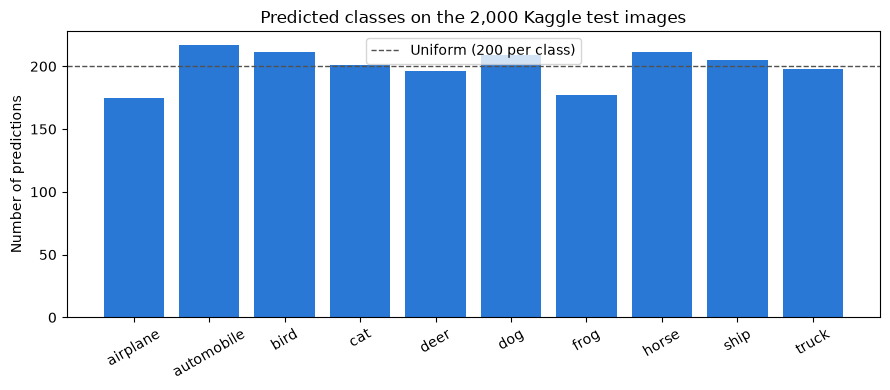

In [6]:
sub = pd.read_csv('Final_submission_fulldata_arch_B_1200_low_weight_decay.csv')
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
counts = sub['label'].value_counts().reindex(range(10), fill_value=0)

print(f'Predictions: {len(sub):,}')
for i, name in enumerate(classes):
    print(f'  {i} {name:<10} {counts[i]:4d}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(classes, counts.values, color='#2a78d6')
ax.axhline(len(sub) / 10, color='#52514e', linestyle='--', linewidth=1, label='Uniform (200 per class)')
ax.set_ylabel('Number of predictions')
ax.set_title('Predicted classes on the 2,000 Kaggle test images')
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()